# Why Python For Finance

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import pandas_datareader.data as web
import matplotlib

/var/folders/mk/tmsmks1d5hvf_npfq7z9ttpw0000gn/T/ipykernel_69597/2517690442.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  goog = yf.download("goog", start = "2009-03-14", end = "2014-04-14", progress = False)
Matplotlib is building the font cache; this may take a moment.


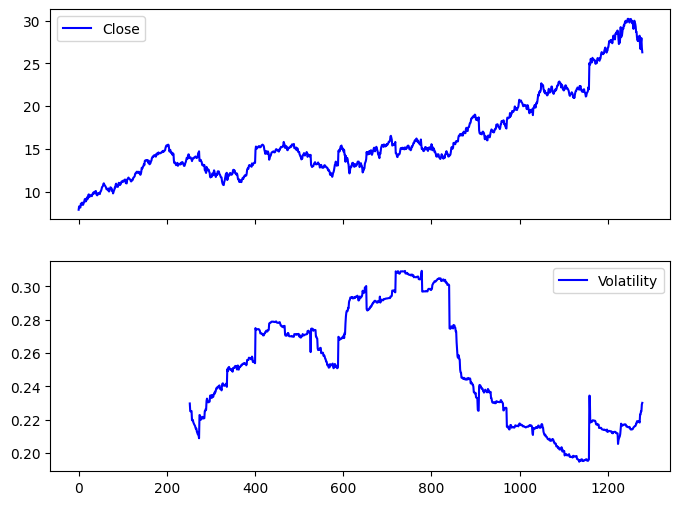

In [2]:
# google data
goog = yf.download("goog", start = "2009-03-14", end = "2014-04-14", progress = False)
goog.columns = goog.columns.get_level_values('Price') # remove multi-index

goog = (
    goog
    .reset_index()
    .assign(
        Log_Ret = lambda d: np.log(d['Close'] / d['Close'].shift(1)),
        Volatility = lambda d: d['Log_Ret'].rolling(window = 252).std() * np.sqrt(252)
    )
)


# plot volatility
%matplotlib inline
goog[['Close', 'Volatility']].plot(subplots = True, color = 'blue', figsize = (8, 6));